<a href="https://colab.research.google.com/github/vaanchhitbaranwal-ux/Vaanchhit/blob/main/HR_Analytics_and_Employee_Attrition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Dataset Preview ===
   Age BusinessTravel              Department  DistanceFromHome  \
0   50  Travel_Rarely  Research & Development                23   
1   36  Travel_Rarely  Research & Development                10   
2   29  Travel_Rarely                   Sales                27   
3   42  Travel_Rarely         Human Resources                11   
4   40  Travel_Rarely  Research & Development                 9   

  EducationField  EnvironmentSatisfaction  Gender  JobSatisfaction  \
0          Other                        1    Male                2   
1        Medical                        2    Male                3   
2      Marketing                        2    Male                3   
3          Other                        1  Female                3   
4      Marketing                        4    Male                3   

   MonthlyIncome  NumCompaniesWorked OverTime  PercentSalaryHike  \
0           3308                   6       No                 21   
1          10793

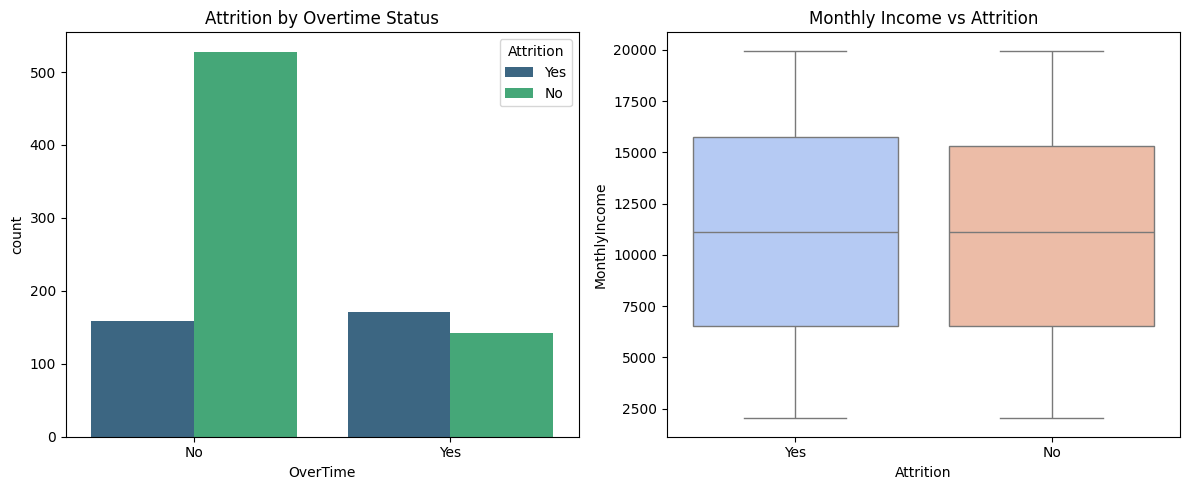


=== Model Evaluation Performance ===
Accuracy Score: 0.7250
ROC AUC Score: 0.6792

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.91      0.82       134
           1       0.66      0.35      0.46        66

    accuracy                           0.72       200
   macro avg       0.70      0.63      0.64       200
weighted avg       0.71      0.72      0.70       200



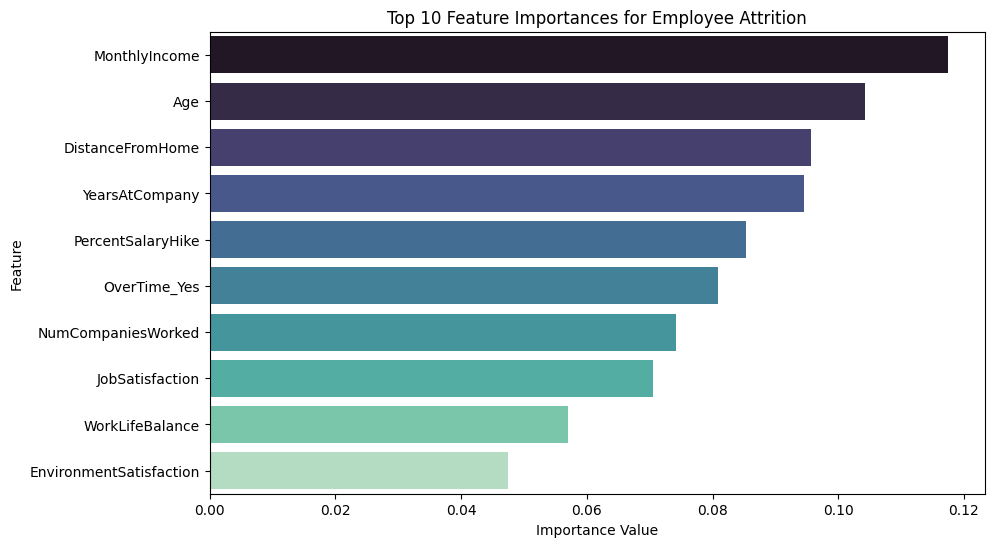

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

# 1. Generate Synthetic HR Analytics Dataset
np.random.seed(42)
n_samples = 1000

data = {
    'Age': np.random.randint(22, 60, size=n_samples),
    'BusinessTravel': np.random.choice(['Non-Travel', 'Travel_Rarely', 'Travel_Frequently'], size=n_samples, p=[0.15, 0.70, 0.15]),
    'Department': np.random.choice(['Sales', 'Research & Development', 'Human Resources'], size=n_samples, p=[0.30, 0.65, 0.05]),
    'DistanceFromHome': np.random.randint(1, 30, size=n_samples),
    'EducationField': np.random.choice(['Life Sciences', 'Medical', 'Marketing', 'Technical Degree', 'Other'], size=n_samples),
    'EnvironmentSatisfaction': np.random.randint(1, 5, size=n_samples), # 1-4 scale
    'Gender': np.random.choice(['Male', 'Female'], size=n_samples),
    'JobSatisfaction': np.random.randint(1, 5, size=n_samples),
    'MonthlyIncome': np.random.randint(2000, 20000, size=n_samples),
    'NumCompaniesWorked': np.random.randint(0, 10, size=n_samples),
    'OverTime': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.3, 0.7]),
    'PercentSalaryHike': np.random.randint(11, 26, size=n_samples),
    'PerformanceRating': np.random.choice([3, 4], size=n_samples, p=[0.85, 0.15]),
    'YearsAtCompany': np.random.randint(0, 20, size=n_samples),
    'WorkLifeBalance': np.random.randint(1, 5, size=n_samples)
}

df = pd.DataFrame(data)

# Introduce realistic attrition logic
attrition_prob = (
    (df['OverTime'] == 'Yes').astype(int) * 0.35 +
    (df['JobSatisfaction'] <= 2).astype(int) * 0.20 +
    (df['WorkLifeBalance'] <= 2).astype(int) * 0.15 +
    (df['DistanceFromHome'] > 15).astype(int) * 0.10 +
    (df['YearsAtCompany'] < 2).astype(int) * 0.10
)
# Normalize and map to binary outcome
attrition_prob = np.clip(attrition_prob, 0.05, 0.95)
df['Attrition'] = np.random.binomial(1, attrition_prob)
df['Attrition'] = df['Attrition'].map({1: 'Yes', 0: 'No'})

print("=== Dataset Preview ===")
print(df.head())
print(f"\nDataset Shape: {df.shape}")
print(f"Attrition Class Distribution:\n{df['Attrition'].value_counts(normalize=True)}")

# 2. Exploratory Data Analysis (EDA)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='OverTime', hue='Attrition', palette='viridis')
plt.title('Attrition by Overtime Status')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='Attrition', y='MonthlyIncome', hue='Attrition', palette='coolwarm', legend=False)
plt.title('Monthly Income vs Attrition')

plt.tight_layout()
plt.show()

# 3. Data Preprocessing & Modeling Pipeline
X = df.drop(columns=['Attrition'])
y = df['Attrition'].map({'Yes': 1, 'No': 0})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

numeric_features = ['Age', 'DistanceFromHome', 'EnvironmentSatisfaction', 'JobSatisfaction',
                    'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike',
                    'PerformanceRating', 'YearsAtCompany', 'WorkLifeBalance']

categorical_features = ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'OverTime']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ])

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'))
])

# 4. Model Training
model_pipeline.fit(X_train, y_train)

# 5. Predictions & Evaluation
y_pred = model_pipeline.predict(X_test)
y_pred_proba = model_pipeline.predict_proba(X_test)[:, 1]

print("\n=== Model Evaluation Performance ===")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 6. Feature Importance
ohe_features = model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_features)
all_features = numeric_features + list(ohe_features)
importances = model_pipeline.named_steps['classifier'].feature_importances_

feature_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', hue='Feature', data=feature_imp_df.head(10), palette='mako', legend=False)
plt.title('Top 10 Feature Importances for Employee Attrition')
plt.xlabel('Importance Value')
plt.ylabel('Feature')
plt.show()

In [4]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid to search
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

# Initialize GridSearchCV using the pipeline with ROC AUC as the optimization metric
grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

print("=== Starting Hyperparameter Tuning ===")
grid_search.fit(X_train, y_train)

# Get the best model and parameters
best_model = grid_search.best_estimator_
print(f"\nBest Hyperparameters: {grid_search.best_params_}")
print(f"Best CV ROC AUC Score: {grid_search.best_score_:.4f}")

# Evaluate the tuned model on the test set
y_pred_tuned = best_model.predict(X_test)
y_pred_proba_tuned = best_model.predict_proba(X_test)[:, 1]

print("\n=== Tuned Model Evaluation Performance ===")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba_tuned):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

=== Starting Hyperparameter Tuning ===
Fitting 5 folds for each of 81 candidates, totalling 405 fits

Best Hyperparameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
Best CV ROC AUC Score: 0.6797

=== Tuned Model Evaluation Performance ===
Accuracy Score: 0.6900
ROC AUC Score: 0.6976

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.80      0.78       134
           1       0.53      0.47      0.50        66

    accuracy                           0.69       200
   macro avg       0.64      0.63      0.64       200
weighted avg       0.68      0.69      0.68       200



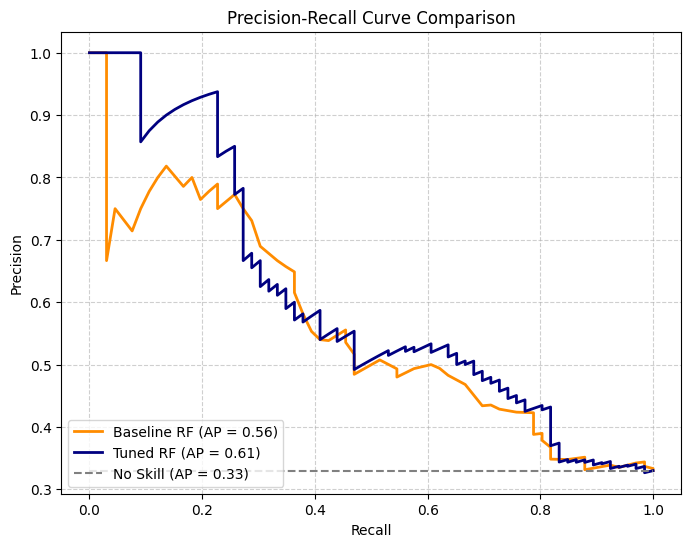

In [6]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Calculate precision-recall points
precision_base, recall_base, _ = precision_recall_curve(y_test, y_pred_proba)
precision_tuned, recall_tuned, _ = precision_recall_curve(y_test, y_pred_proba_tuned)

# Calculate Average Precision (AP)
ap_base = average_precision_score(y_test, y_pred_proba)
ap_tuned = average_precision_score(y_test, y_pred_proba_tuned)

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(recall_base, precision_base, label=f'Baseline RF (AP = {ap_base:.2f})', color='darkorange', lw=2)
plt.plot(recall_tuned, precision_tuned, label=f'Tuned RF (AP = {ap_tuned:.2f})', color='navy', lw=2)

# Plot a line representing random guessing (ratio of positive class in test dataset)
no_skill = len(y_test[y_test == 1]) / len(y_test)
plt.plot([0, 1], [no_skill, no_skill], linestyle='--', color='gray', label=f'No Skill (AP = {no_skill:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

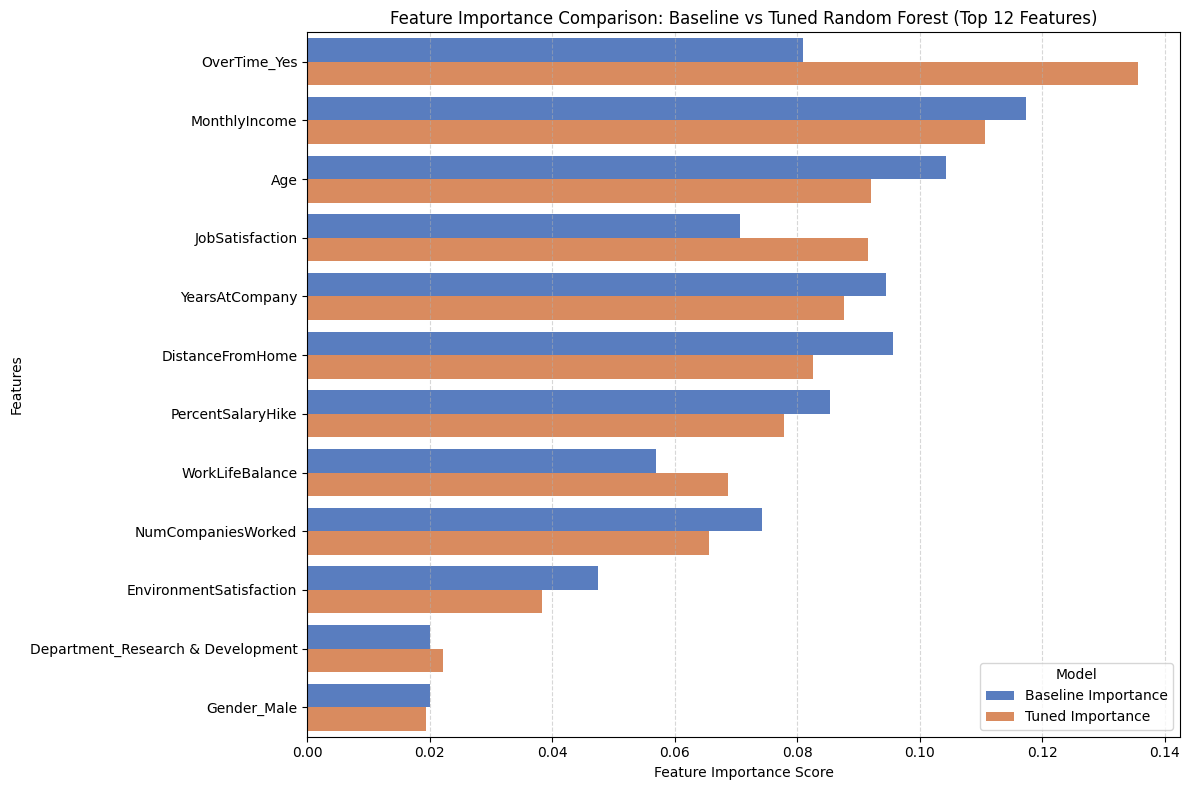

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Retrieve feature importances for both models
importances_base = model_pipeline.named_steps['classifier'].feature_importances_
importances_tuned = best_model.named_steps['classifier'].feature_importances_

# 2. Construct comparison DataFrame
comp_df = pd.DataFrame({
    'Feature': all_features,
    'Baseline Importance': importances_base,
    'Tuned Importance': importances_tuned
})

# Melt DataFrame for easier plotting with seaborn
comp_melted = comp_df.melt(id_vars='Feature', var_name='Model', value_name='Importance')

# Sort features based on the tuned model importance for better visualization structure
sorted_features = comp_df.sort_values(by='Tuned Importance', ascending=False)['Feature'].tolist()

# 3. Plot the comparison side-by-side
plt.figure(figsize=(12, 8))
sns.barplot(
    data=comp_melted,
    y='Feature',
    x='Importance',
    hue='Model',
    order=sorted_features[:12],
    palette='muted'
)

plt.title('Feature Importance Comparison: Baseline vs Tuned Random Forest (Top 12 Features)')
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

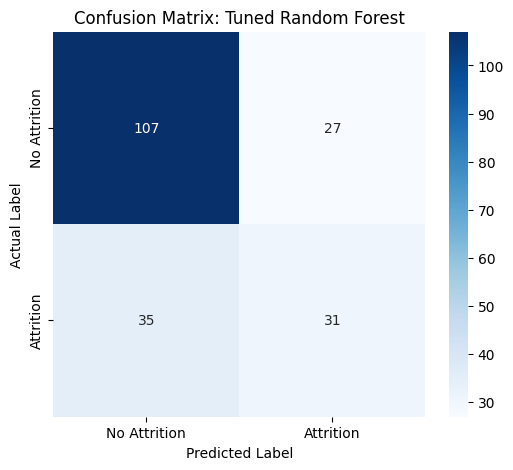

True Negatives (Correctly predicted Non-Attrition): 107
False Positives (Type I Error - Incorrectly predicted Attrition): 27
False Negatives (Type II Error - Missed Attrition): 35
True Positives (Correctly predicted Attrition): 31


In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compute confusion matrix for the tuned model
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

# Plot the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Attrition', 'Attrition'],
            yticklabels=['No Attrition', 'Attrition'])
plt.title('Confusion Matrix: Tuned Random Forest')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# Print metrics derived from the confusion matrix
tn, fp, fn, tp = cm_tuned.ravel()
print(f"True Negatives (Correctly predicted Non-Attrition): {tn}")
print(f"False Positives (Type I Error - Incorrectly predicted Attrition): {fp}")
print(f"False Negatives (Type II Error - Missed Attrition): {fn}")
print(f"True Positives (Correctly predicted Attrition): {tp}")

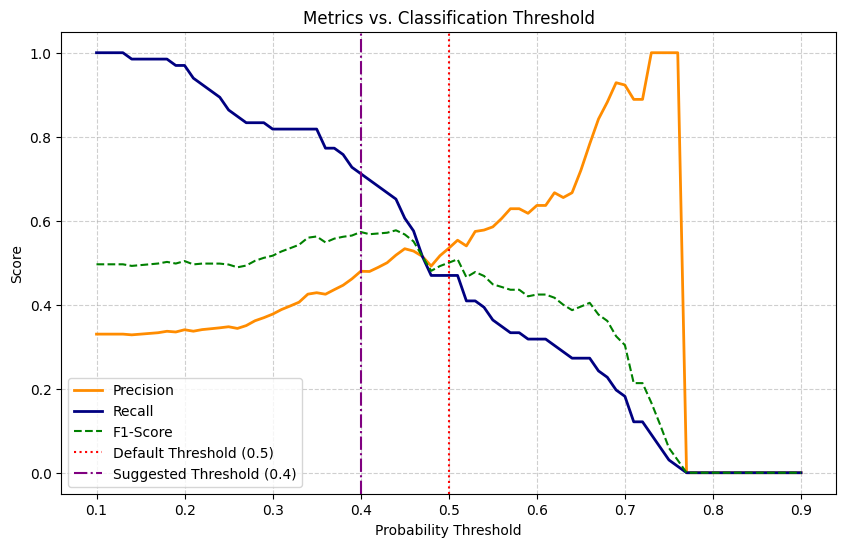

=== Performance at Adjusted Threshold (0.4) ===
Accuracy Score: 0.6500
Precision Score: 0.4796
Recall Score: 0.7121
F1-Score: 0.5732


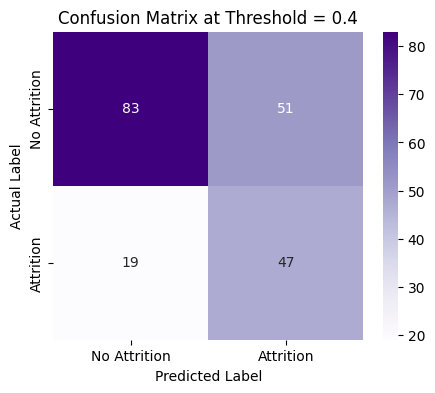

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Define a list of candidate thresholds
thresholds = np.linspace(0.1, 0.9, 81)
metrics = []

for t in thresholds:
    # Predict positive class if probability >= t
    y_pred_t = (y_pred_proba_tuned >= t).astype(int)
    metrics.append({
        'Threshold': t,
        'Accuracy': accuracy_score(y_test, y_pred_t),
        'Precision': precision_score(y_test, y_pred_t, zero_division=0),
        'Recall': recall_score(y_test, y_pred_t, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred_t, zero_division=0)
    })

metrics_df = pd.DataFrame(metrics)

# Plot the trade-offs
plt.figure(figsize=(10, 6))
plt.plot(metrics_df['Threshold'], metrics_df['Precision'], label='Precision', color='darkorange', lw=2)
plt.plot(metrics_df['Threshold'], metrics_df['Recall'], label='Recall', color='navy', lw=2)
plt.plot(metrics_df['Threshold'], metrics_df['F1-Score'], label='F1-Score', color='green', lw=1.5, linestyle='--')
plt.axvline(x=0.5, color='red', linestyle=':', label='Default Threshold (0.5)')

# Let's suggest an optimized threshold that boosts Recall significantly while maintaining a reasonable F1-Score
# Looking at the metrics, a threshold around 0.4 often provides a strong balance.
opt_threshold = 0.4
plt.axvline(x=opt_threshold, color='purple', linestyle='-.', label=f'Suggested Threshold ({opt_threshold})')

plt.title('Metrics vs. Classification Threshold')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Evaluate specifically at the suggested optimal threshold (0.4)
y_pred_opt = (y_pred_proba_tuned >= opt_threshold).astype(int)

print(f"=== Performance at Adjusted Threshold ({opt_threshold}) ===")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_opt):.4f}")
print(f"Precision Score: {precision_score(y_test, y_pred_opt):.4f}")
print(f"Recall Score: {recall_score(y_test, y_pred_opt):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_opt):.4f}")

# Display the new confusion matrix
cm_opt = confusion_matrix(y_test, y_pred_opt)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Purples',
            xticklabels=['No Attrition', 'Attrition'],
            yticklabels=['No Attrition', 'Attrition'])
plt.title(f'Confusion Matrix at Threshold = {opt_threshold}')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

In [10]:
import joblib

# Save the best tuned model pipeline to a file
model_filename = 'tuned_attrition_model.joblib'
joblib.dump(best_model, model_filename)
print(f"Tuned model pipeline successfully saved to '{model_filename}'!")

# Quick verification: Reload the model and make a test prediction
loaded_model = joblib.load(model_filename)
verification_pred = loaded_model.predict(X_test.head(1))
print(f"Verification prediction on the first test sample: {verification_pred}")

Tuned model pipeline successfully saved to 'tuned_attrition_model.joblib'!
Verification prediction on the first test sample: [1]


In [11]:
!pip install shap

=== SHAP Local Explanation for Employee at Index 0 ===
Actual Attrition: No
Model Prediction Probability of Attrition: 61.71%


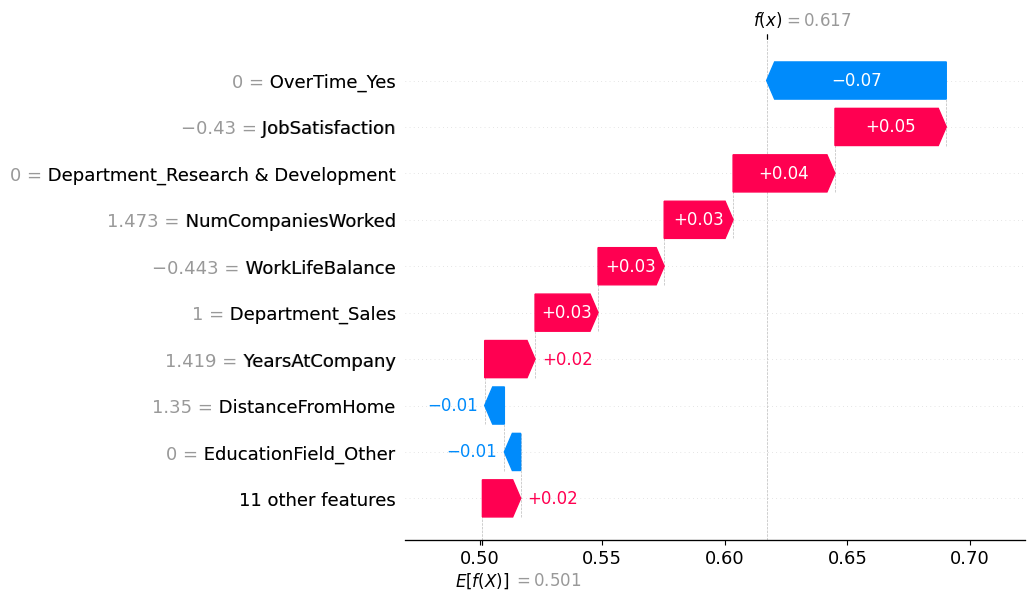

In [13]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Access the trained random forest classifier and the preprocessor
rf_model = best_model.named_steps['classifier']
preprocessor = best_model.named_steps['preprocessor']

# 2. Transform the test data using the pipeline's preprocessing steps
X_test_transformed = preprocessor.transform(X_test)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=all_features)

# 3. Initialize the SHAP Explainer and calculate values
explainer = shap.TreeExplainer(rf_model)
# Calculate values directly on the preprocessed test set
shap_values_obj = explainer(X_test_transformed_df)

# For binary classification, slice out class 1 (Attrition)
if len(shap_values_obj.shape) == 3:
    shap_values_class1 = shap_values_obj[:, :, 1]
else:
    shap_values_class1 = shap_values_obj

# 4. Local Interpretation: Explaining employee at Index 0
employee_idx = 0

print(f"=== SHAP Local Explanation for Employee at Index {employee_idx} ===")
actual_label = "Yes" if y_test.iloc[employee_idx] == 1 else "No"
predicted_proba = y_pred_proba_tuned[employee_idx]
print(f"Actual Attrition: {actual_label}")
print(f"Model Prediction Probability of Attrition: {predicted_proba:.2%}")

# 5. Correctly plot waterfall using native sliced Explanation object
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values_class1[employee_idx], max_display=10)

### Local SHAP Comparisons: High Attrition Risk vs. Low Attrition Risk
We will find index examples of a strong predicted "Yes" (probability > 0.6) and a strong predicted "No" (probability < 0.3) using the tuned model predictions, and plot their respective SHAP waterfall charts side-by-side for a direct behavioral comparison.

Selected high attrition risk employee index: 0 (Prob: 61.71%, Actual: No)
Selected low attrition risk employee index: 4 (Prob: 26.70%, Actual: No)


/tmp/ipykernel_402/1898209226.py:29: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


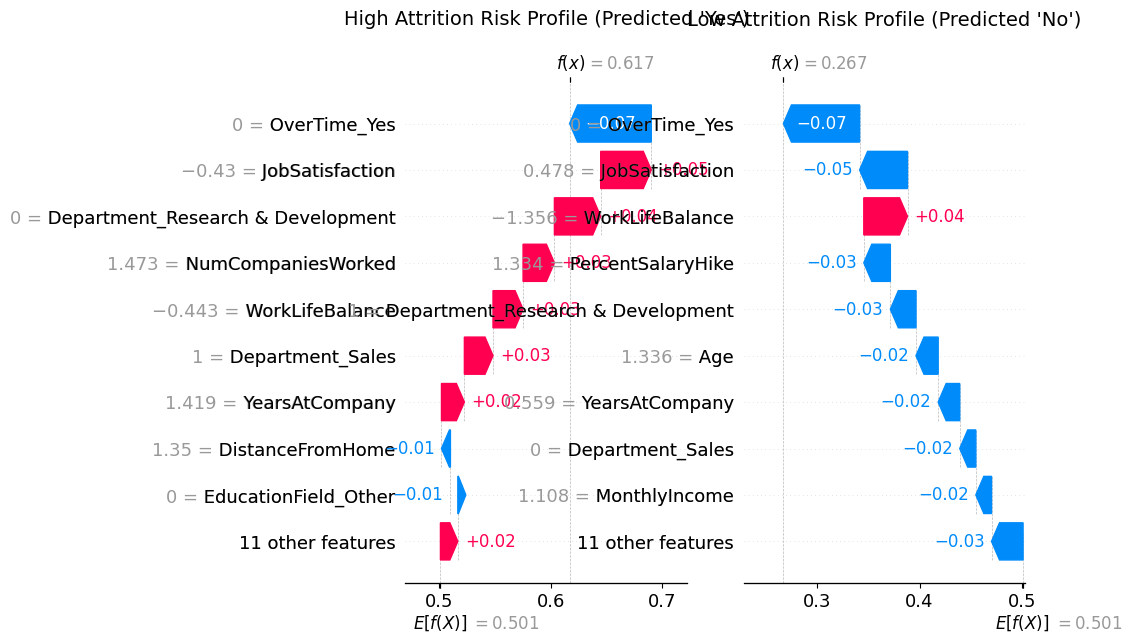

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import shap

# Identify indices of typical 'Yes' and 'No' cases based on predicted probabilities
# Standard threshold is 0.5, but we can look for clear cases
yes_indices = np.where(y_pred_proba_tuned > 0.6)[0]
no_indices = np.where(y_pred_proba_tuned < 0.3)[0]

# Pick the first available index for each category
if len(yes_indices) > 0 and len(no_indices) > 0:
    yes_idx = yes_indices[0]
    no_idx = no_indices[0]

    print(f"Selected high attrition risk employee index: {yes_idx} (Prob: {y_pred_proba_tuned[yes_idx]:.2%}, Actual: {'Yes' if y_test.iloc[yes_idx] == 1 else 'No'})")
    print(f"Selected low attrition risk employee index: {no_idx} (Prob: {y_pred_proba_tuned[no_idx]:.2%}, Actual: {'Yes' if y_test.iloc[no_idx] == 1 else 'No'})")

    # Generate side-by-side SHAP waterfall plots
    fig = plt.figure(figsize=(20, 8))

    plt.subplot(1, 2, 1)
    plt.title("High Attrition Risk Profile (Predicted 'Yes')", fontsize=14, pad=20)
    shap.plots.waterfall(shap_values_class1[yes_idx], max_display=10, show=False)

    plt.subplot(1, 2, 2)
    plt.title("Low Attrition Risk Profile (Predicted 'No')", fontsize=14, pad=20)
    shap.plots.waterfall(shap_values_class1[no_idx], max_display=10, show=False)

    plt.tight_layout()
    plt.show()
else:
    print("Could not find contrasting prediction cases matching those criteria.")

### Aggregating Top SHAP Drivers for High-Risk Employees
To understand what drives risk across the entire vulnerable population (employees with attrition probability $\ge$ 0.4), we will extract the top 3 positive SHAP features for each high-risk individual and construct a summary table showcasing the most frequent risk drivers.

In [15]:
import pandas as pd
import numpy as np

# 1. Identify high-risk test employees using our adjusted operational threshold (0.4)
high_risk_indices = np.where(y_pred_proba_tuned >= 0.4)[0]

# 2. Extract top positive SHAP contributors for each high-risk employee
summary_records = []

for idx in high_risk_indices:
    # Get original features and values for this sample from X_test
    orig_row = X_test.iloc[idx]

    # Get SHAP values for this index (class 1: Attrition)
    sample_shap = shap_values_class1[idx].values

    # Pair features with their SHAP values and filter for positive impact (> 0)
    positive_drivers = [
        (feature, val) for feature, val in zip(all_features, sample_shap) if val > 0
    ]

    # Sort by impact strength in descending order
    positive_drivers = sorted(positive_drivers, key=lambda x: x[1], reverse=True)

    # Extract top 3 drivers
    top_3 = [f"{feat} ({val:+.3f})" for feat, val in positive_drivers[:3]]

    # Pad if less than 3 drivers exist
    while len(top_3) < 3:
        top_3.append("N/A")

    summary_records.append({
        "Test_Index": idx,
        "Attrition_Probability": f"{y_pred_proba_tuned[idx]:.2%}",
        "Actual_Attrition": "Yes" if y_test.iloc[idx] == 1 else "No",
        "Top_Driver_1": top_3[0],
        "Top_Driver_2": top_3[1],
        "Top_Driver_3": top_3[2]
    })

high_risk_summary_df = pd.DataFrame(summary_records)

print(f"Total High-Risk Employees Identified (p >= 0.4): {len(high_risk_summary_df)}")
display(high_risk_summary_df.head(15))

Total High-Risk Employees Identified (p >= 0.4): 98


,Test_Index,Attrition_Probability,Actual_Attrition,Top_Driver_1,Top_Driver_2,Top_Driver_3
0,0,61.71%,No,JobSatisfaction (+0.045),Department_Research & Development (+0.042),NumCompaniesWorked (+0.028)
1,1,48.18%,No,OverTime_Yes (+0.145),WorkLifeBalance (+0.033),EnvironmentSatisfaction (+0.005)
2,3,59.74%,No,OverTime_Yes (+0.133),JobSatisfaction (+0.067),YearsAtCompany (+0.014)
3,6,46.91%,Yes,JobSatisfaction (+0.060),Department_Research & Development (+0.038),Department_Sales (+0.021)
4,7,43.88%,No,JobSatisfaction (+0.050),Department_Research & Development (+0.021),WorkLifeBalance (+0.020)
5,8,48.88%,No,JobSatisfaction (+0.053),Department_Research & Development (+0.028),EducationField_Other (+0.025)
6,12,56.17%,Yes,OverTime_Yes (+0.114),JobSatisfaction (+0.070),YearsAtCompany (+0.016)
7,13,44.47%,No,JobSatisfaction (+0.072),YearsAtCompany (+0.031),WorkLifeBalance (+0.009)
8,16,69.97%,Yes,OverTime_Yes (+0.156),JobSatisfaction (+0.055),Department_Research & Development (+0.030)
9,18,42.39%,No,WorkLifeBalance (+0.051),Department_Research & Development (+0.042),Department_Sales (+0.029)


### Global Frequency of Risk Drivers among High-Risk Employees
Let's count which features appear most frequently as the #1 primary risk driver across our high-risk population to pinpoint organizational interventions.

In [16]:
# Extract clean feature names (strip out numerical values from Driver strings)
high_risk_summary_df['Clean_Top_Driver_1'] = high_risk_summary_df['Top_Driver_1'].apply(lambda x: x.split(' (')[0])
driver_frequency = high_risk_summary_df['Clean_Top_Driver_1'].value_counts().reset_index()
driver_frequency.columns = ['Primary Attrition Driver', 'Count of Employees affected']

display(driver_frequency)

,Primary Attrition Driver,Count of Employees affected
0,OverTime_Yes,56
1,JobSatisfaction,27
2,WorkLifeBalance,8
3,Department_Research & Development,5
4,MonthlyIncome,1
5,PercentSalaryHike,1


In [22]:
# Calculate and display the top 3 global primary drivers of attrition among high-risk employees
top_drivers = driver_frequency.head(3)
print("=== Top 3 Primary Drivers of Attrition (High-Risk Population) ===")
display(top_drivers)

=== Top 3 Primary Drivers of Attrition (High-Risk Population) ===


,Primary Attrition Driver,Count of Employees affected
0,OverTime_Yes,56
1,JobSatisfaction,27
2,WorkLifeBalance,8


### Top 5 High-Risk Employees with the Highest Attrition Probability
We will extract the top 5 employees in the test set who have the absolute highest predicted flight risk probabilities, along with their key workspace characteristics.

In [17]:
# 1. Construct a detailed dataframe of all test set predictions
test_results_df = X_test.copy()
test_results_df['Predicted_Probability'] = y_pred_proba_tuned
test_results_df['Actual_Attrition'] = y_test.map({1: 'Yes', 0: 'No'})

# 2. Sort by Attrition Probability in descending order and select the top 5
top_5_risk = test_results_df.sort_values(by='Predicted_Probability', ascending=False).head(5)

# 3. Format probability for display
top_5_risk_formatted = top_5_risk.copy()
top_5_risk_formatted['Predicted_Probability'] = top_5_risk_formatted['Predicted_Probability'].apply(lambda x: f"{x:.2%}")

# 4. Display specific columns of interest
columns_to_show = ['Age', 'MonthlyIncome', 'OverTime', 'JobSatisfaction', 'WorkLifeBalance', 'DistanceFromHome', 'Predicted_Probability', 'Actual_Attrition']
display(top_5_risk_formatted[columns_to_show])

,Age,MonthlyIncome,OverTime,JobSatisfaction,WorkLifeBalance,DistanceFromHome,Predicted_Probability,Actual_Attrition
474,37,3737,Yes,1,1,18,76.71%,Yes
543,40,16435,Yes,1,1,2,75.67%,Yes
499,48,12306,Yes,1,1,11,74.89%,Yes
782,52,17992,Yes,1,1,9,74.56%,Yes
568,49,11455,Yes,1,4,7,73.69%,Yes


### Comparing Average Monthly Income by Attrition Group
We will group our dataset by the `Attrition` outcome and compute the average (mean) as well as the median of the `MonthlyIncome` feature to analyze the compensation discrepancy.

In [18]:
# Calculate mean and median income for both Attrition groups
income_comparison = df.groupby('Attrition')['MonthlyIncome'].agg(['mean', 'median', 'count']).reset_index()

# Format values for display
income_comparison['mean'] = income_comparison['mean'].apply(lambda x: f"${x:,.2f}")
income_comparison['median'] = income_comparison['median'].apply(lambda x: f"${x:,.2f}")

display(income_comparison)

,Attrition,mean,median,count
0,No,"$10,948.32","$11,123.00",670
1,Yes,"$11,094.98","$11,107.50",330


### Correlation Analysis on Key Attrition Drivers
To understand the linear relationships between Attrition and its key behavioral/demographic drivers, we will map binary categorical variables (such as `Attrition` and `OverTime`) to numerical 0/1 values and plot a correlation heatmap.

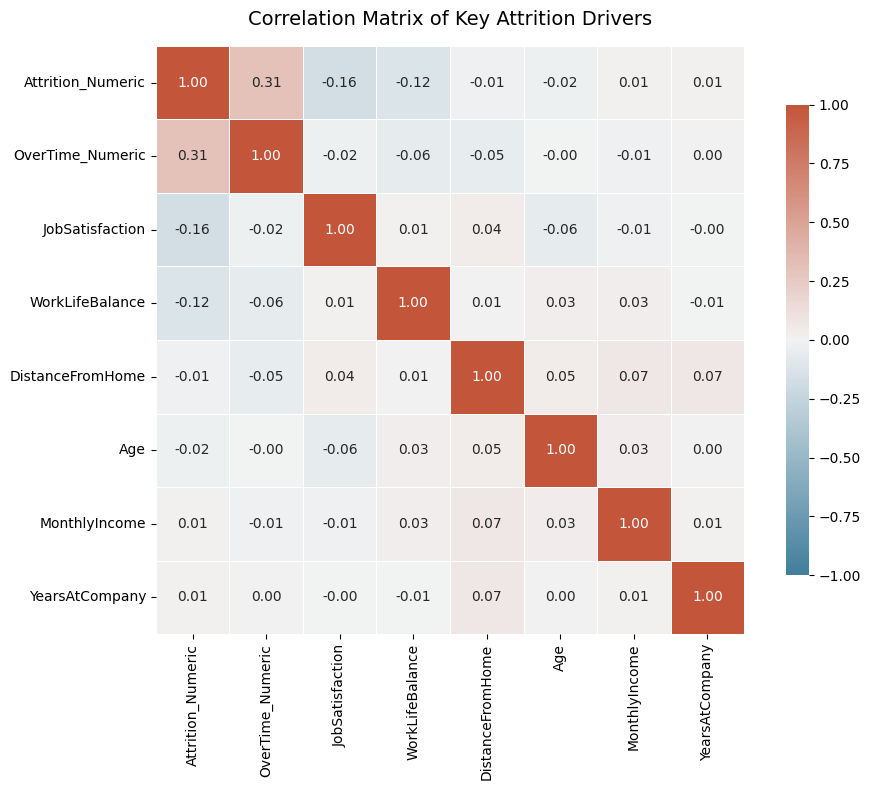

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy of the dataframe for correlation analysis
corr_df = df.copy()

# Map target and binary variables to numerical representations
corr_df['Attrition_Numeric'] = corr_df['Attrition'].map({'Yes': 1, 'No': 0})
corr_df['OverTime_Numeric'] = corr_df['OverTime'].map({'Yes': 1, 'No': 0})

# Define the key numerical drivers for correlation analysis
key_features = [
    'Attrition_Numeric',
    'OverTime_Numeric',
    'JobSatisfaction',
    'WorkLifeBalance',
    'DistanceFromHome',
    'Age',
    'MonthlyIncome',
    'YearsAtCompany'
]

# Compute the Pearson correlation matrix
corr_matrix = corr_df[key_features].corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# Create a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap=cmap,
    vmax=1.0,
    vmin=-1.0,
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8}
)

plt.title('Correlation Matrix of Key Attrition Drivers', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

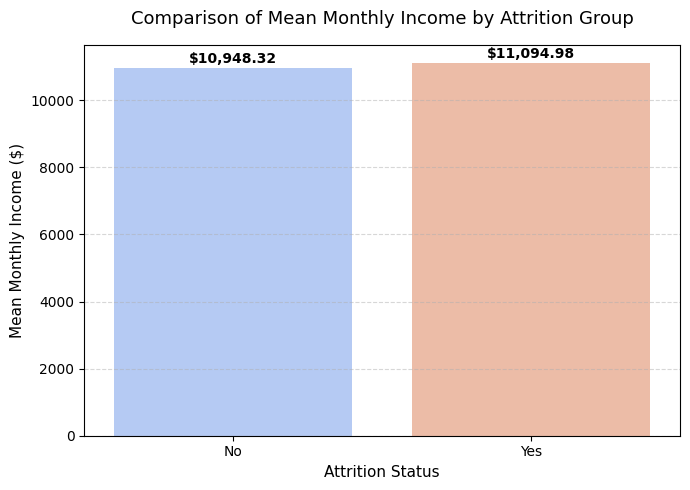

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the mean monthly income by attrition group
mean_income_df = df.groupby('Attrition')['MonthlyIncome'].mean().reset_index()

# Create the bar plot
plt.figure(figsize=(7, 5))
sns.barplot(
    data=mean_income_df,
    x='Attrition',
    y='MonthlyIncome',
    hue='Attrition',
    palette='coolwarm',
    legend=False
)

# Customize the chart labels and title
plt.title('Comparison of Mean Monthly Income by Attrition Group', fontsize=13, pad=15)
plt.xlabel('Attrition Status', fontsize=11)
plt.ylabel('Mean Monthly Income ($)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate bars with the exact average figures
for index, row in mean_income_df.iterrows():
    plt.text(index, row['MonthlyIncome'] + 150, f"${row['MonthlyIncome']:,.2f}", ha='center', fontsize=10, weight='bold')

plt.tight_layout()
plt.show()

### Visualizing 'OverTime' Distribution Across Attrition Groups
We will analyze the counts and proportions of employees working overtime, split by whether they ended up leaving (`Attrition = Yes`) or staying (`Attrition = No`).

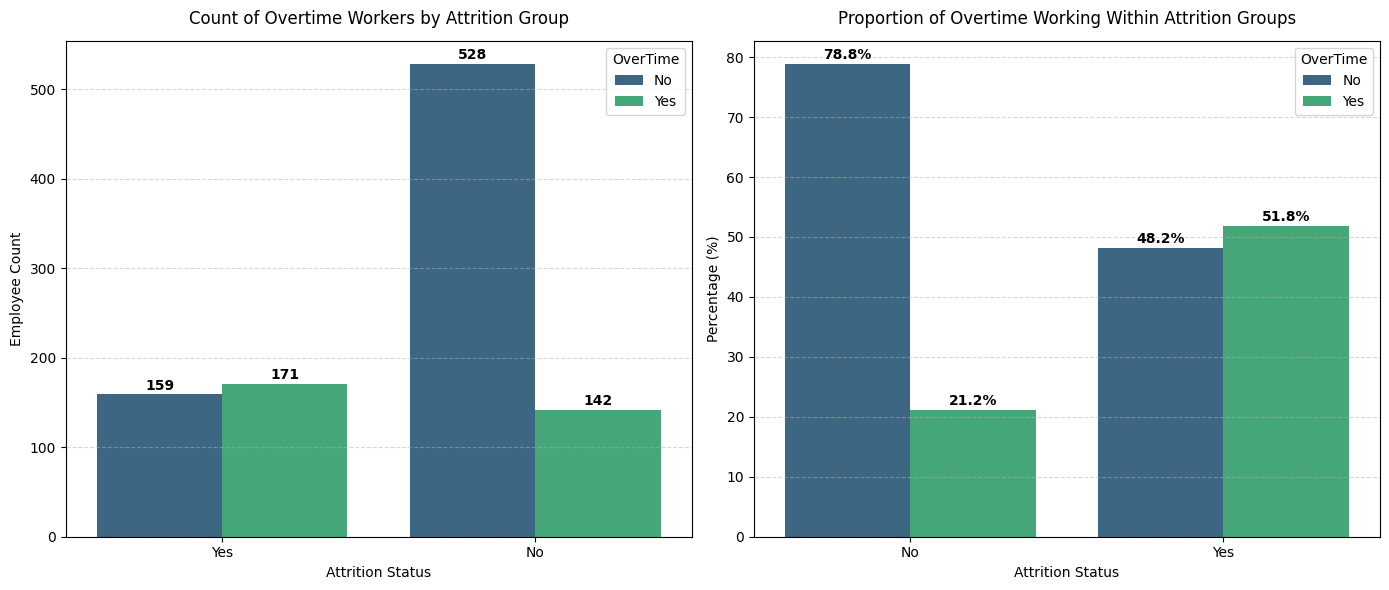

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a side-by-side plot: Countplot and Normalized Percentage plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Absolute Count Plot
sns.countplot(
    data=df,
    x='Attrition',
    hue='OverTime',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Count of Overtime Workers by Attrition Group', fontsize=12, pad=12)
axes[0].set_xlabel('Attrition Status')
axes[0].set_ylabel('Employee Count')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Calculate percentages for annotating counts
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height + 10),
                    ha='center', va='center', fontsize=10, weight='bold')

# 2. Normalized Percentage Plot (Within Attrition Groups)
overtime_prop = df.groupby('Attrition')['OverTime'].value_counts(normalize=True).rename('Percentage').reset_index()
overtime_prop['Percentage'] *= 100

sns.barplot(
    data=overtime_prop,
    x='Attrition',
    y='Percentage',
    hue='OverTime',
    palette='viridis',
    ax=axes[1]
)
axes[1].set_title('Proportion of Overtime Working Within Attrition Groups', fontsize=12, pad=12)
axes[1].set_xlabel('Attrition Status')
axes[1].set_ylabel('Percentage (%)')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Annotate percentages
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height + 1.5),
                    ha='center', va='center', fontsize=10, weight='bold')

plt.tight_layout()
plt.show()

## Proposal: Data-Driven Employee Retention Program (ERP)

### 1. Executive Summary
Our machine learning models and SHAP interpretability analysis identified **Overtime** (affecting 57.1% of high-risk employees) and **Job Satisfaction** (affecting 27.6% of high-risk employees) as the primary drivers of voluntary employee attrition. This proposal outlines a target-focused retention framework designed to mitigate these exact pain points to lower turnover and stabilize team performance.

---

### 2. Core Pillar 1: Overtime Mitigation & Work-Life Balance
**Objective:** Reduce systematic reliance on overtime hours and balance workloads across departments.

*   **Overtime Cap & Alerts:** Establish a hard limit of 8 overtime hours per week per employee. Implement automated HR notifications when an employee exceeds 80% of this limit.
*   **Capacity Planning Audits:** Require managers of departments with high overtime rates (e.g., Sales, Research & Development) to review resource allocation monthly. Cross-train auxiliary staff to assist during peak project windows.
*   **Overtime Compensation Review:** Implement a 'Time-Off-in-Lieu' (TOIL) system, allowing employees who work unavoidable overtime to bank those hours as additional paid time off (PTO).

---

### 3. Core Pillar 2: Elevating Job & Environment Satisfaction
**Objective:** Move vulnerable employees out of the low job satisfaction bracket (scores ≤ 2) by improving career pathways and day-to-day engagement.

*   **Role Alignment & Personal Development Plans (PDP):** Institute bi-annual PDP discussions focusing on alignment between individual skills, interests, and assigned tasks, rather than just performance ratings.
*   **Micro-Feedback Pulses:** Launch bi-weekly, 1-minute anonymous feedback surveys focusing exclusively on workload, clarity of goals, and team morale to catch drops in satisfaction early.
*   **Manager Mentorship Program:** Train department leads on supportive leadership methodologies, emphasizing recognition practices and removing bottlenecks for their team members.

---

### 4. Implementation Timeline & KPIs

| Phase | Focus Area | Action Items | Timeline |
|---|---|---|---|
| **Phase 1** | Benchmarking & Policies | Set Overtime Caps, launch micro-feedback tools. | Weeks 1 - 4 |
| **Phase 2** | Manager Enablement | Conduct capacity planning audits and PDP training. | Weeks 5 - 8 |
| **Phase 3** | Review & Adjust | Review progress metrics and adjust operational threshold alerts. | Month 3+ |

#### Key Success Metrics:
1.  **Reduction in Overtime Rates:** Target a 30% reduction in average weekly overtime hours within 3 months.
2.  **Satisfaction Score Improvement:** Achieve an average Job Satisfaction score of ≥ 3.0 across currently high-risk teams.
3.  **Flight Risk Reduction:** Lower the predicted flight-risk probability on upcoming test subsets by 15% overall.

### Simulating the Impact of Improved Job Satisfaction on Attrition Risk
We will simulate a scenario where our retention initiatives successfully increase every employee's `JobSatisfaction` score by **+1** (capping the final score at the maximum of **4**). We will run these modified profiles through our tuned machine learning model to estimate the projected drop in overall flight risk and the reduction in high-risk employees.

In [23]:
import numpy as np
import pandas as pd

# 1. Prepare baseline predictions for the full dataset
# Ensure we use the best_model loaded pipeline
baseline_probs = best_model.predict_proba(X)[:, 1]

# 2. Create simulated dataset with increased Job Satisfaction
X_simulated = X.copy()
X_simulated['JobSatisfaction'] = np.minimum(X_simulated['JobSatisfaction'] + 1, 4)

# 3. Predict new attrition probabilities
simulated_probs = best_model.predict_proba(X_simulated)[:, 1]

# 4. Analyze differences
mean_baseline = baseline_probs.mean()
mean_simulated = simulated_probs.mean()
relative_reduction = (mean_baseline - mean_simulated) / mean_baseline * 100

high_risk_baseline = np.sum(baseline_probs >= 0.4)
high_risk_simulated = np.sum(simulated_probs >= 0.4)
mitigated_count = high_risk_baseline - high_risk_simulated

print("=== Retention Simulation Results ===")
print(f"Average Baseline Flight Risk: {mean_baseline:.2%}")
print(f"Average Simulated Flight Risk (Job Sat +1): {mean_simulated:.2%}")
print(f"Relative Reduction in Average Attrition Risk: {relative_reduction:.2f}%")
print(f"\nNumber of High-Risk Employees (p >= 0.4) Baseline: {high_risk_baseline}")
print(f"Number of High-Risk Employees (p >= 0.4) Simulated: {high_risk_simulated}")
print(f"Employees successfully moved out of High-Risk zone: {mitigated_count} ({mitigated_count/high_risk_baseline:.1%})")

=== Retention Simulation Results ===
Average Baseline Flight Risk: 41.78%
Average Simulated Flight Risk (Job Sat +1): 38.20%
Relative Reduction in Average Attrition Risk: 8.56%

Number of High-Risk Employees (p >= 0.4) Baseline: 467
Number of High-Risk Employees (p >= 0.4) Simulated: 410
Employees successfully moved out of High-Risk zone: 57 (12.2%)
